In [1]:
import numpy as np
import pygambit as gbt
from itertools import combinations
from scipy.optimize import linprog
import random
import re
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import plotly.graph_objects as go

In [2]:
value_p = dict()
value_m = dict()

v_max = 6
v_min = 3

# returns a penalty that is quadratic in the total speed with params a, b, c
# all params should be nonpositive (players do not want to crash)
# allow a = 0 if you want a linear penalty for example.
def crash_value_quadratic(s, a , b , c):
    (d, v1, v2) = s
    if d != 0:
        raise ValueError("not a crash state")

    v = v1+ v2

    return a*v**2 + b*v + c


In [3]:
crash_states = []
for v_p in range(v_min, v_max+1):
    for v_m in range(v_min, v_max+1):
        crash_states.append((0, v_p,v_m))

for state in crash_states:
    # + player recieves linear penalty for crashing
    value_p[state] = crash_value_quadratic(state, -0.01, -1, 0)

    # - player receives constant penalty for crashing
    value_m[state] = crash_value_quadratic(state, -0.01, -1, -1)

# swerve state value. consider introducing a scaling param to compare with crash values
value_p["s+"] = -5
value_p["s-"] = 5
value_p["s0"] = -2

value_m["s+"] = 2
value_m["s-"] = -2
value_m["s0"] = 0    

values = {1: value_p, -1: value_m}

strat_p = dict()
strat_m = dict()
strats = {1: strat_p, -1: strat_m}

In [4]:
# transition kernel
# inputs: current state, player 1 action,  player -1 action
# output: dict() keys = states, values = probabilities of reaching corresponding key state
def kernel(s, a_p, a_m):
    if type(s) == str:
        return {s: 1}
    
    (d, v_p, v_m) = s

    if d == 0:
        return {s: 1}

    if a_p == "swerve" and a_m == "swerve":
        return {"s0": 1}
        
    if a_p == "swerve":
        return {"s+": 1}
        
    if a_m == "swerve":
        return {"s-": 1}

    return {(max(d - v_p - v_m,0) , v_p + a_p, v_m + a_m): 1}

In [5]:
def expected_future_value(s, a_p, a_m, player):
    
    future_states = kernel(s, a_p, a_m)
    total = 0

    for (state, probability) in future_states.items():
        total += probability*values[player][state]

    return total

In [6]:
def check_degeneracy(P, tol=1e-9):
    """
    P is the payoff matrix of the opponent whose best
    responses we are counting.

    The mixed strategy is played by the player choosing
    rows of P.

    Returns True if a degeneracy witness is found.
    """

    m, n = P.shape
    scale = max(1.0, np.max(np.abs(P)))
    tol_abs = tol * scale

    # Enumerate supports of the mixing player
    for k in range(1, min(m, n)):

        for S in combinations(range(m), k):

            # Enumerate k+1 candidate best responses
            for T in combinations(range(n), k + 1):

                t0 = T[0]

                # Variables: probabilities p[0:k], epsilon
                c = np.zeros(k + 1)
                c[-1] = -1  # maximize epsilon

                A_eq = []
                b_eq = []

                # Probabilities sum to one
                A_eq.append([1.0] * k + [0.0])
                b_eq.append(1.0)

                # All strategies in T must have equal payoff
                for t in T[1:]:
                    row = P[list(S), t] - P[list(S), t0]
                    A_eq.append(list(row) + [0.0])
                    b_eq.append(0.0)

                A_ub = []
                b_ub = []

                # T must consist of best responses
                for j in range(n):
                    row = P[list(S), j] - P[list(S), t0]
                    A_ub.append(list(row) + [0.0])
                    b_ub.append(tol_abs)

                # Every probability must be at least epsilon
                for i in range(k):
                    row = np.zeros(k + 1)
                    row[i] = -1
                    row[-1] = 1
                    A_ub.append(row)
                    b_ub.append(0.0)

                result = linprog(
                    c,
                    A_ub=np.array(A_ub),
                    b_ub=np.array(b_ub),
                    A_eq=np.array(A_eq),
                    b_eq=np.array(b_eq),
                    bounds=[(0, None)] * (k + 1),
                    method="highs"
                )

                if result.success and result.x[-1] > tol:
                    return [S,T,result.x,True]

    return [False]


def is_degenerate(A, B, tol=1e-9):
    """
    Check both players for degeneracy.
    A: row player's payoff matrix
    B: column player's payoff matrix
    """

    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)

    if A.shape != B.shape or A.ndim != 2:
        raise ValueError("A and B must have the same 2D shape.")

    if max(A.shape) > 4:
        raise ValueError("This implementation supports games up to 4x4.")

    check_B = check_degeneracy(B, tol)
    if check_B[-1]:
        
        print("p1 mixed strategy:", check_B[0])
        print("mixture:", check_B[2][0:-1])
        print("p2 optimal responses:", check_B[1])
        
        return True

    check_AT = check_degeneracy(A.T, tol)
    if check_degeneracy(A.T, tol)[-1]:
        
        print("p2 mixed strategy:", check_AT[0])
        print("mixture:", check_AT[2][0:-1])
        print("p1 optimal responses:", check_AT[1])
        
        return True

    return False


In [7]:
def extract_results(result1, result2, game):

    eq1 = result1.equilibria
    eq2 = result2.equilibria
    
    # Extract probability vectors for both players
    def extract(eq):
        strategies = list(eq.mixed_strategies())
    
        x = np.array([p for _, p in strategies[0][1]], dtype=float)
        y = np.array([p for _, p in strategies[1][1]], dtype=float)
    
        return x, y
    
    Eq1 = [{
            "value": (eq.payoff(game.players['1']),eq.payoff(game.players['2'])),
            "strat": extract(eq)
        } for eq in eq1]
    Eq2 = [{
            "value": (eq.payoff(game.players['1']),eq.payoff(game.players['2'])),
            "strat": extract(eq)
        } for eq in eq2]

    return Eq1, Eq2

def compare_equilibria(Eq1, Eq2,
                       name1="Mixed Solver",
                       name2="LCP Solver",
                       tol=1e-7):

    E1 = [e["strat"] for e in Eq1]
    E2 = [e["strat"] for e in Eq2]

    # Distance between two equilibria
    def distance(e1, e2):
        dx = np.max(np.abs(e1[0] - e2[0]))
        dy = np.max(np.abs(e1[1] - e2[1]))
        return max(dx, dy)

    # Construct graph of possible matches
    # An edge exists if two equilibria are within tolerance.
    adjacency = [
        [j for j, e2 in enumerate(E2)
         if distance(e1, e2) <= tol]
        for e1 in E1
    ]

    # Maximum bipartite matching (avoids dependence on ordering)
    match2 = {}

    def augment(i, visited):
        for j in adjacency[i]:
            if j in visited:
                continue

            visited.add(j)

            if j not in match2 or augment(match2[j], visited):
                match2[j] = i
                return True

        return False

    for i in range(len(E1)):
        augment(i, set())

    # Recover matched pairs
    match1 = {i: j for j, i in match2.items()}

    unmatched1 = [i for i in range(len(E1))
                  if i not in match1]

    unmatched2 = [j for j in range(len(E2))
                  if j not in match2]

    # Display results
    
    # print("\n" + "=" * 65)
    # print("EQUILIBRIUM COMPARISON")
    # print("=" * 65)

    # print(f"{name1}: {len(E1)} equilibria")
    # print(f"{name2}: {len(E2)} equilibria")
    # print(f"Matching equilibria: {len(match1)}")
    # print(f"Tolerance: {tol:g}")
    

    matched = not unmatched1 and not unmatched2
    if not matched:
        print("\nWARNING: The two solvers disagree!")

        if unmatched1:
            print(f"\nEquilibria found only by {name1}:")
            for i in unmatched1:
                print(f"\nEquilibrium {i+1}:")
                print("Row:   ", E1[i][0])
                print("Column:", E1[i][1])

        if unmatched2:
            print(f"\nEquilibria found only by {name2}:")
            for j in unmatched2:
                print(f"\nEquilibrium {j+1}:")
                print("Row:   ", E2[j][0])
                print("Column:", E2[j][1])
    
    return matched

In [8]:
def get_mixed_eqs(Eq):
    result = []
    for eq in Eq: 
        strat_p = eq["strat"][0]
        strat_m = eq["strat"][1]

        if np.any(strat_p % 1 != 0) or np.any(strat_m % 1 != 0):
            result.append(eq)
    return result

In [9]:

def evaluate_state(s):
    # this function should never be called on a terminal state
    # without loss of generality we can assume s = (d, v+, v-)
    (d, v_p, v_m) = s

    A_p = ["swerve", 0]
    A_m = ["swerve", 0]

    if v_p < v_max:
        A_p.append(1)
    if v_p > v_min:
        A_p.append(-1)
    if v_m < v_max:
        A_m.append(1)
    if v_m > v_min:
        A_m.append(-1)

    m = len(A_p)
    n = len(A_m)

    payout_p = np.zeros((m,n))
    payout_m = np.zeros((m,n))

    for i in range(m):
        for j in range(n):
            payout_p[i][j] += expected_future_value(s, A_p[i], A_m[j], 1)
            if type(A_p[i]) == int:
                payout_p[i][j] += 0.1*(A_p[i])
                # payout_p[i][j] += 0.1*1/(A_p[i]+0.1)
                # payout_m[i][j] -= 0.1*A_p[i]
            payout_m[i][j] += expected_future_value(s, A_p[i], A_m[j], -1)
            if type(A_m[j]) == int:
                payout_m[i][j] += 0.1*(A_m[j])
                # payout_p[i][j] -= 0.1*A_m[j]
                # payout_m[i][j] += 0.1*1/(A_m[j]+0.1)

    # print(payout_p)
    # print(payout_m)
    
    if is_degenerate(payout_p, payout_m):
        print("degenerate")
        return

    # game = nash.Game(payout_p, payout_m)
    game = gbt.Game.from_arrays(payout_p, payout_m)

    # equilibria = list(game.support_enumeration())
    mixed_result = gbt.nash.enummixed_solve(game,rational=False)
    lcp_result = gbt.nash.lcp_solve(game, rational=False, use_strategic=True)

    Eq1, Eq2 = extract_results(mixed_result, lcp_result, game)
    matched = compare_equilibria(Eq1, Eq2, "Mixed Solver", "LCP Solver", 1e-7)    

    if not matched:
        print("unmatched")
        return
        
    return Eq1
    # for i, data in enumerate(Eq1):
    #     print(f"Equilibrium {i+1}:")
    #     print("Player 1:", data["strat"][0], data["value"][0] )
    #     print("Player 2:", data["strat"][1], data["value"][1])

In [10]:
def solve_game():
    for d in range(1, 10):
        for v1 in range(v_min, v_max+1):
            for v2 in range(v_min, v_max+1):
                print(d,v1,v2)
                if d > 1 and d <= v1 + v2:
                    values[1][(d,v1,v2)] = values[1][(d-1,v1,v2)]
                    values[-1][(d,v1,v2)] = values[-1][(d-1,v1,v2)]
                    strats[1][(d,v1,v2)] = strats[1][(d-1,v1,v2)]
                    strats[-1][(d,v1,v2)] = strats[-1][(d-1,v1,v2)]
                    continue
            
                Eq = evaluate_state((d,v1,v2))
                n = len(Eq)
                if n > 1:
                    print("Multiple equilibria:",n)
                    mixed_Eqs = get_mixed_eqs(Eq)
                    Eq = mixed_Eqs
                i = random.randint(0,len(Eq)-1)
                values[1][(d,v1,v2)] = Eq[i]["value"][0]
                values[-1][(d,v1,v2)] = Eq[i]["value"][1]
                strats[1][(d,v1,v2)] = Eq[i]["strat"][0]
                strats[-1][(d,v1,v2)] = Eq[i]["strat"][1]
                

            
        

In [11]:
solve_game()

1 3 3
Multiple equilibria: 3
1 3 4
Multiple equilibria: 3
1 3 5
Multiple equilibria: 3
1 3 6
Multiple equilibria: 3
1 4 3
Multiple equilibria: 3
1 4 4
Multiple equilibria: 3
1 4 5
Multiple equilibria: 3
1 4 6
Multiple equilibria: 3
1 5 3
Multiple equilibria: 3
1 5 4
Multiple equilibria: 3
1 5 5
Multiple equilibria: 3
1 5 6
Multiple equilibria: 3
1 6 3
Multiple equilibria: 3
1 6 4
Multiple equilibria: 3
1 6 5
Multiple equilibria: 3
1 6 6
Multiple equilibria: 3
2 3 3
2 3 4
2 3 5
2 3 6
2 4 3
2 4 4
2 4 5
2 4 6
2 5 3
2 5 4
2 5 5
2 5 6
2 6 3
2 6 4
2 6 5
2 6 6
3 3 3
3 3 4
3 3 5
3 3 6
3 4 3
3 4 4
3 4 5
3 4 6
3 5 3
3 5 4
3 5 5
3 5 6
3 6 3
3 6 4
3 6 5
3 6 6
4 3 3
4 3 4
4 3 5
4 3 6
4 4 3
4 4 4
4 4 5
4 4 6
4 5 3
4 5 4
4 5 5
4 5 6
4 6 3
4 6 4
4 6 5
4 6 6
5 3 3
5 3 4
5 3 5
5 3 6
5 4 3
5 4 4
5 4 5
5 4 6
5 5 3
5 5 4
5 5 5
5 5 6
5 6 3
5 6 4
5 6 5
5 6 6
6 3 3
6 3 4
6 3 5
6 3 6
6 4 3
6 4 4
6 4 5
6 4 6
6 5 3
6 5 4
6 5 5
6 5 6
6 6 3
6 6 4
6 6 5
6 6 6
7 3 3
7 3 4
7 3 5
7 3 6
7 4 3
7 4 4
7 4 5
7 4 6
7 5 3
7 

In [12]:
for key, value in values[1].items():
    print(key, value)

(0, 3, 3) -6.36
(0, 3, 4) -7.49
(0, 3, 5) -8.64
(0, 3, 6) -9.81
(0, 4, 3) -7.49
(0, 4, 4) -8.64
(0, 4, 5) -9.81
(0, 4, 6) -11.0
(0, 5, 3) -8.64
(0, 5, 4) -9.81
(0, 5, 5) -11.0
(0, 5, 6) -12.21
(0, 6, 3) -9.81
(0, 6, 4) -11.0
(0, 6, 5) -12.21
(0, 6, 6) -13.44
s+ -5
s- 5
s0 -2
(1, 3, 3) -4.511961722488039
(1, 3, 4) -4.511961722488039
(1, 3, 5) -4.212855637513171
(1, 3, 6) -3.9736842105263164
(1, 4, 3) -4.476076555023924
(1, 4, 4) -4.476076555023923
(1, 4, 5) -4.181243414120127
(1, 4, 6) -3.9454887218045123
(1, 5, 3) -4.181243414120126
(1, 5, 4) -4.181243414120127
(1, 5, 5) -3.945488721804512
(1, 5, 6) -3.7527519051651144
(1, 6, 3) -3.9454887218045114
(1, 6, 4) -3.9454887218045105
(1, 6, 5) -3.7527519051651135
(1, 6, 6) -3.592307692307692
(2, 3, 3) -4.511961722488039
(2, 3, 4) -4.511961722488039
(2, 3, 5) -4.212855637513171
(2, 3, 6) -3.9736842105263164
(2, 4, 3) -4.476076555023924
(2, 4, 4) -4.476076555023923
(2, 4, 5) -4.181243414120127
(2, 4, 6) -3.9454887218045123
(2, 5, 3) -4.1812434

In [13]:
print(values[1])

{(0, 3, 3): -6.36, (0, 3, 4): -7.49, (0, 3, 5): -8.64, (0, 3, 6): -9.81, (0, 4, 3): -7.49, (0, 4, 4): -8.64, (0, 4, 5): -9.81, (0, 4, 6): -11.0, (0, 5, 3): -8.64, (0, 5, 4): -9.81, (0, 5, 5): -11.0, (0, 5, 6): -12.21, (0, 6, 3): -9.81, (0, 6, 4): -11.0, (0, 6, 5): -12.21, (0, 6, 6): -13.44, 's+': -5, 's-': 5, 's0': -2, (1, 3, 3): -4.511961722488039, (1, 3, 4): -4.511961722488039, (1, 3, 5): -4.212855637513171, (1, 3, 6): -3.9736842105263164, (1, 4, 3): -4.476076555023924, (1, 4, 4): -4.476076555023923, (1, 4, 5): -4.181243414120127, (1, 4, 6): -3.9454887218045123, (1, 5, 3): -4.181243414120126, (1, 5, 4): -4.181243414120127, (1, 5, 5): -3.945488721804512, (1, 5, 6): -3.7527519051651144, (1, 6, 3): -3.9454887218045114, (1, 6, 4): -3.9454887218045105, (1, 6, 5): -3.7527519051651135, (1, 6, 6): -3.592307692307692, (2, 3, 3): -4.511961722488039, (2, 3, 4): -4.511961722488039, (2, 3, 5): -4.212855637513171, (2, 3, 6): -3.9736842105263164, (2, 4, 3): -4.476076555023924, (2, 4, 4): -4.4760765

In [14]:
def arr_to_dict(s, arr, player):
    result = dict()
    if len(arr) == 4:
        labels = ["swerve", "do nothing", "speed up", "slow down"]
    else:
        vel = s[player]
        if vel == v_min:
            labels = ["swerve", "do nothing", "speed up"]
        else: 
            labels = ["swerve", "do nothing", "slow down"]

    for i in range(len(arr)):
        if arr[i] > 0:
            result[labels[i]] = arr[i]

    return result

strats_nice = {1: {}, -1:{}}

for s in strats[1]:
    strats_nice[1][s] = arr_to_dict(s, strats[1][s], 1)
    strats_nice[-1][s] = arr_to_dict(s, strats[-1][s], -1)


In [15]:
print(strats_nice[-1])

{(1, 3, 3): {'swerve': np.float64(0.16267942583732056), 'do nothing': np.float64(0.8373205741626796)}, (1, 3, 4): {'swerve': np.float64(0.16267942583732065), 'slow down': np.float64(0.8373205741626794)}, (1, 3, 5): {'swerve': np.float64(0.26238145416227593), 'slow down': np.float64(0.737618545837724)}, (1, 3, 6): {'swerve': np.float64(0.3421052631578948), 'slow down': np.float64(0.6578947368421053)}, (1, 4, 3): {'swerve': np.float64(0.1746411483253589), 'do nothing': np.float64(0.8253588516746412)}, (1, 4, 4): {'swerve': np.float64(0.1746411483253589), 'slow down': np.float64(0.8253588516746411)}, (1, 4, 5): {'swerve': np.float64(0.27291886195995785), 'slow down': np.float64(0.7270811380400423)}, (1, 4, 6): {'swerve': np.float64(0.3515037593984961), 'slow down': np.float64(0.6484962406015039)}, (1, 5, 3): {'swerve': np.float64(0.2729188619599579), 'do nothing': np.float64(0.7270811380400422)}, (1, 5, 4): {'swerve': np.float64(0.27291886195995785), 'slow down': np.float64(0.727081138040

## Visualizations

Run **`solve_game()`** and the **`strats_nice`** cell before these plots. Every figure uses the same state `(d, v+, v−)`: remaining distance and the two speeds. Color is player `+`'s continuation value \(V_+\).

Three views follow:

1. **Matplotlib 3D** — static snapshot of the value cloud.
2. **Plotly 3D** — hover, crash/swerve markers, and an equilibrium-trajectory picker.
3. **Plotly heatmap** — one distance slice at a time, with a slider on \(d\).


### Static 3D scatter (Matplotlib)

Each point is a numeric state. Color is \(V_+\). The black path starts at `(9, 6, 6)` and at every step moves to a **successor with the largest \(V_+\)**.

That greedy walk is a quick way to see high-value regions. It is **not** mixed-strategy equilibrium play (the Plotly figure below follows modal equilibrium actions instead).



Greedy (max-value successor) trajectory:

(9, 6, 6)  value =  -3.592307692307692
s-  value =  5

Maximum value: -3.592307692307692

States with maximal value:
(1, 6, 6)
(2, 6, 6)
(3, 6, 6)
(4, 6, 6)
(5, 6, 6)
(6, 6, 6)
(7, 6, 6)
(8, 6, 6)
(9, 6, 6)


/var/folders/v_/cdgtnh8555s_tk3sx9lxhhnm0000gn/T/ipykernel_54960/557251813.py:191: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


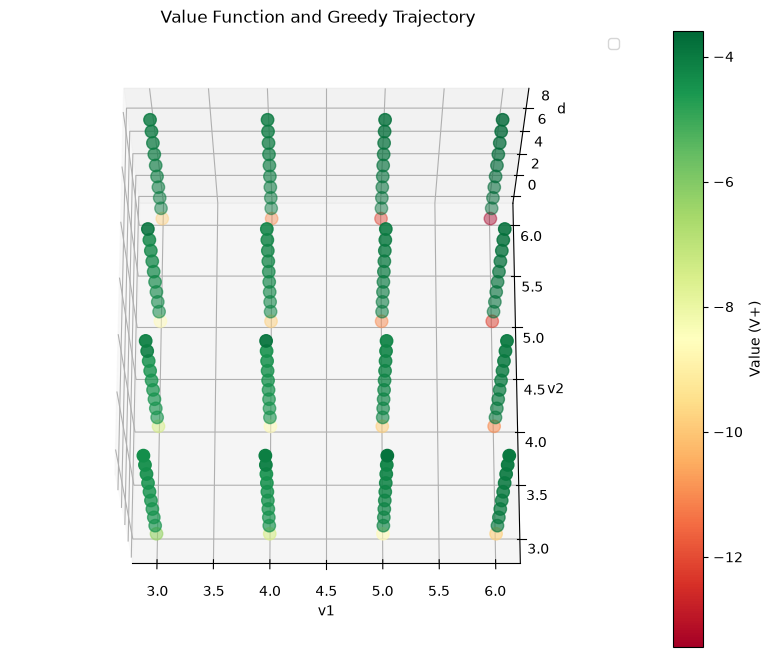

In [16]:
# Interactive plots from values / strats (run solve_game and arr_to_dict first).
ACTION_FROM_LABEL = {
    "swerve": "swerve",
    "do nothing": 0,
    "speed up": 1,
    "slow down": -1,
}


def format_strat(s, player):
    nice = strats_nice[player].get(s, {})
    if not nice:
        return "—"
    return ", ".join(f"{lab} {p:.2f}" for lab, p in nice.items())


def swerve_prob(s, player):
    return float(strats_nice[player].get(s, {}).get("swerve", 0.0))


def modal_action(s, player):
    nice = strats_nice[player].get(s, {})
    if not nice:
        return 0
    label = max(nice, key=nice.get)
    return ACTION_FROM_LABEL[label]


def equilibrium_trajectory(start, max_steps=20):
    """Follow modal mixed-strategy actions through the transition kernel."""
    path = [start]
    if isinstance(start, str) or (isinstance(start, tuple) and start[0] == 0):
        return path

    seen = {start}
    current = start
    for _ in range(max_steps):
        a_p = modal_action(current, 1)
        a_m = modal_action(current, -1)
        dist = kernel(current, a_p, a_m)
        nxt = max(dist, key=dist.get)
        path.append(nxt)
        if isinstance(nxt, str) or (isinstance(nxt, tuple) and nxt[0] == 0):
            break
        if nxt in seen:
            break
        seen.add(nxt)
        current = nxt
    return path


def trajectory_xyz_text(path):
    numeric = [s for s in path if isinstance(s, tuple)]
    xs = [s[1] for s in numeric]
    ys = [s[2] for s in numeric]
    zs = [s[0] for s in numeric]
    texts = []
    for i, s in enumerate(numeric):
        nxt = path[i + 1] if i + 1 < len(path) else "terminal"
        texts.append(
            f"step {i}<br>state = {s}<br>"
            f"V+ = {values[1].get(s, float('nan')):.6g}<br>"
            f"V- = {values[-1].get(s, float('nan')):.6g}<br>"
            f"+ strat: {format_strat(s, 1)}<br>"
            f"- strat: {format_strat(s, -1)}<br>"
            f"next = {nxt}"
        )
    return xs, ys, zs, texts, numeric


player_values = values[1]
state_values = {k: v for k, v in player_values.items() if isinstance(k, tuple)}
terminal_values = {k: v for k, v in player_values.items() if isinstance(k, str)}

rows = []
for (d, v1, v2), vp in state_values.items():
    s = (d, v1, v2)
    p_sw_p = swerve_prob(s, 1)
    p_sw_m = swerve_prob(s, -1)
    if d == 0:
        kind = "crash"
    elif max(p_sw_p, p_sw_m) >= 0.5:
        kind = "likely swerve"
    else:
        kind = "interior"
    rows.append(
        {
            "d": d,
            "v1": v1,
            "v2": v2,
            "value_p": vp,
            "value_m": values[-1].get(s, float("nan")),
            "kind": kind,
            "hover": (
                f"state = ({d}, {v1}, {v2})<br>"
                f"{'CRASH' if d == 0 else 'in motion'}<br>"
                f"V+ = {vp:.6g}<br>"
                f"V- = {values[-1].get(s, float('nan')):.6g}<br>"
                f"+ strat: {format_strat(s, 1)}<br>"
                f"- strat: {format_strat(s, -1)}<br>"
                f"P(+ swerve) = {p_sw_p:.2f}<br>"
                f"P(- swerve) = {p_sw_m:.2f}"
            ),
        }
    )

df = pd.DataFrame(rows)
cmin, cmax = df["value_p"].min(), df["value_p"].max()

style = {
    "crash": dict(symbol="diamond", size=8, name="crash (d = 0)"),
    "likely swerve": dict(symbol="square", size=6, name="likely swerve (P ≥ 0.5)"),
    "interior": dict(symbol="circle", size=5, name="interior"),
}

# ============================================================
# Static 3D visualization (Matplotlib)
# ============================================================
# Greedy path: from each state, step to a successor with largest V+.
# This is the original snapshot plot; it is not mixed-strategy play.

def successors(state):
    d, v1, v2 = state
    succ = ["s+", "s-", "s0"]
    for a1 in [-1, 0, 1]:
        for a2 in [-1, 0, 1]:
            ns = (max(0, d - v1 - v2), v1 + a1, v2 + a2)
            if ns in state_values:
                succ.append(ns)
    return succ

G = nx.DiGraph()
for s, v in state_values.items():
    G.add_node(s, value=v)
for terminal, v in terminal_values.items():
    G.add_node(terminal, value=v)
for s in state_values:
    for nxt in successors(s):
        G.add_edge(s, nxt)
for terminal in terminal_values:
    G.add_edge(terminal, terminal)

INITIAL_STATE = (9, 6, 6)
trajectory = [INITIAL_STATE]
visited = {INITIAL_STATE}
current = INITIAL_STATE
while True:
    succ = list(G.successors(current))
    if len(succ) == 0:
        break
    best = max(succ, key=lambda s: G.nodes[s]["value"])
    trajectory.append(best)
    if isinstance(best, str) or best in visited:
        break
    visited.add(best)
    current = best

print("\nGreedy (max-value successor) trajectory:\n")
for state in trajectory:
    print(state, " value = ", G.nodes[state]["value"])

max_value = max(state_values.values())
print("\nMaximum value:", max_value)
print("\nStates with maximal value:")
for s, v in state_values.items():
    if abs(v - max_value) < 1e-9:
        print(s)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(
    df["v1"], df["v2"], df["d"],
    c=df["value_p"], cmap="RdYlGn", s=80,
)
traj_numeric = [s for s in trajectory if isinstance(s, tuple)]
if len(traj_numeric) > 1:
    xd = [s[0] for s in traj_numeric]
    xv1 = [s[1] for s in traj_numeric]
    xv2 = [s[2] for s in traj_numeric]
    ax.plot(
        xv1, xv2, xd,
        color="black", linewidth=3, marker="o",
        label="greedy trajectory",
    )
ax.view_init(elev=70, azim=-90)
ax.set_xlabel("v1")
ax.set_ylabel("v2")
ax.set_zlabel("d")
ax.set_title("Value Function and Greedy Trajectory")
plt.colorbar(scatter, label="Value (V+)")
plt.legend()
plt.show()


### Interactive 3D landscape (Plotly)

Same axes as the Matplotlib plot, with extra encoding:

| Marker | Meaning |
| --- | --- |
| Diamond | Crash state (`d = 0`) |
| Square | At least one player swerves with probability \(\ge 0.5\) |
| Circle | Other in-motion states |
| Black path | Modal equilibrium trajectory through `kernel` |

**Hover** a point for both players' values, mixed strategies (`swerve` / `do nothing` / `speed up` / `slow down`), and swerve probabilities.

Use the **Start state** dropdown to choose `(d, v+, v−)`. The path uses each player's highest-probability action, not the greedy value walk. Swerve terminals `s+`, `s-`, `s0` show up as `next = ...` in hover; they are not 3D coordinates.


In [17]:
# ============================================================
# 3D value landscape + equilibrium trajectory picker
# ============================================================

fig3d = go.Figure()
for kind, spec in style.items():
    part = df[df["kind"] == kind]
    fig3d.add_trace(
        go.Scatter3d(
            x=part["v1"],
            y=part["v2"],
            z=part["d"],
            mode="markers",
            name=spec["name"],
            text=part["hover"],
            hovertemplate="%{text}<extra></extra>",
            marker=dict(
                size=spec["size"],
                symbol=spec["symbol"],
                color=part["value_p"],
                colorscale="RdYlGn",
                cmin=cmin,
                cmax=cmax,
                colorbar=dict(title="V+") if kind == "crash" else None,
                showscale=(kind == "crash"),
            ),
        )
    )

DEFAULT_START = (9, 6, 6)
if DEFAULT_START not in state_values:
    DEFAULT_START = max(state_values, key=lambda s: (s[0], s[1], s[2]))

starts = sorted(s for s in state_values if s[0] > 0)
default_path = equilibrium_trajectory(DEFAULT_START)
xs, ys, zs, texts, numeric = trajectory_xyz_text(default_path)

print("Default equilibrium trajectory (modal actions) from", DEFAULT_START)
for state in default_path:
    val = values[1].get(state, terminal_values.get(state, float("nan")))
    print(state, " V+ =", val)

fig3d.add_trace(
    go.Scatter3d(
        x=xs,
        y=ys,
        z=zs,
        mode="lines+markers",
        name=f"eq. trajectory {DEFAULT_START}",
        text=texts,
        hovertemplate="%{text}<extra></extra>",
        line=dict(color="black", width=8),
        marker=dict(size=6, color="black"),
    )
)
traj_idx = len(fig3d.data) - 1

buttons = []
for start in starts:
    path = equilibrium_trajectory(start)
    tx, ty, tz, tt, _ = trajectory_xyz_text(path)
    end = path[-1]
    buttons.append(
        dict(
            label=str(start),
            method="restyle",
            args=[
                {
                    "x": [tx],
                    "y": [ty],
                    "z": [tz],
                    "text": [tt],
                    "name": [f"eq. trajectory {start} → {end}"],
                },
                [traj_idx],
            ],
        )
    )

fig3d.update_layout(
    title="Value function V+ (color) with equilibrium trajectory",
    width=950,
    height=750,
    legend=dict(x=0.02, y=0.98),
    scene=dict(
        xaxis_title="v+ (player 1 speed)",
        yaxis_title="v- (player -1 speed)",
        zaxis_title="d (distance)",
        camera=dict(eye=dict(x=0.2, y=-1.6, z=0.9)),
    ),
    updatemenus=[
        dict(
            buttons=buttons,
            direction="down",
            showactive=True,
            x=1.02,
            xanchor="left",
            y=0.55,
            yanchor="middle",
            pad=dict(r=10, t=10),
            bgcolor="white",
        )
    ],
    annotations=[
        dict(
            text="Start state (d, v+, v-)",
            x=1.02,
            y=0.78,
            xref="paper",
            yref="paper",
            showarrow=False,
            xanchor="left",
        )
    ],
)
fig3d.show()



Default equilibrium trajectory (modal actions) from (9, 6, 6)
(9, 6, 6)  V+ = -3.592307692307692
s+  V+ = -5


### Distance heatmap (Plotly)

A $v_+ \times v_-$ slice of $V_+$ at one remaining distance. Drag the **$d$** slider to move from crash (`d = 0`) out to the farthest solved gap.

Hover a cell for \(V_+\), \(V_-\), and both mixed strategies. This view is usually easier than the 3D cloud for comparing speeds at a fixed gap.


In [18]:
# ============================================================
# Heatmap of V+ with a distance slider
# ============================================================

v_range = list(range(v_min, v_max + 1))
d_range = sorted({s[0] for s in state_values})


def heatmap_payload(d):
    z = []
    zm = []
    sp = []
    sm = []
    for v2 in v_range:
        z_row, zm_row, sp_row, sm_row = [], [], [], []
        for v1 in v_range:
            s = (d, v1, v2)
            z_row.append(values[1].get(s, np.nan))
            zm_row.append(values[-1].get(s, np.nan))
            sp_row.append(format_strat(s, 1))
            sm_row.append(format_strat(s, -1))
        z.append(z_row)
        zm.append(zm_row)
        sp.append(sp_row)
        sm.append(sm_row)
    custom = [
        [[zm[i][j], sp[i][j], sm[i][j]] for j in range(len(v_range))]
        for i in range(len(v_range))
    ]
    return z, custom


z0, custom0 = heatmap_payload(d_range[0])
heat = go.Figure(
    data=[
        go.Heatmap(
            x=v_range,
            y=v_range,
            z=z0,
            customdata=custom0,
            colorscale="RdYlGn",
            zmin=cmin,
            zmax=cmax,
            colorbar=dict(title="V+"),
            hovertemplate=(
                "d = %{meta}<br>"
                "v+ = %{x}<br>"
                "v- = %{y}<br>"
                "V+ = %{z:.6g}<br>"
                "V- = %{customdata[0]:.6g}<br>"
                "+ strat: %{customdata[1]}<br>"
                "- strat: %{customdata[2]}<extra></extra>"
            ),
            meta=d_range[0],
        )
    ]
)

frames = []
steps = []
for d in d_range:
    z, custom = heatmap_payload(d)
    frames.append(
        go.Frame(
            name=str(d),
            data=[
                go.Heatmap(
                    x=v_range,
                    y=v_range,
                    z=z,
                    customdata=custom,
                    meta=d,
                )
            ],
        )
    )
    steps.append(
        dict(
            method="animate",
            label=str(d),
            args=[
                [str(d)],
                dict(mode="immediate", frame=dict(duration=0, redraw=True), transition=dict(duration=0)),
            ],
        )
    )

heat.frames = frames
heat.update_layout(
    title="V+ at fixed distance d  (slider)",
    width=700,
    height=650,
    xaxis=dict(title="v+ (player 1 speed)", dtick=1),
    yaxis=dict(title="v- (player -1 speed)", dtick=1, scaleanchor="x"),
    sliders=[
        dict(
            active=0,
            currentvalue=dict(prefix="d = "),
            pad=dict(t=40),
            steps=steps,
        )
    ],
)
heat.show()
